# 04 · Does delivery affect satisfaction? Where does logistics fail?
Delivered orders in the analysis period with a review. Delay = delivered date − estimated
delivery date, in days. This is observational data: the analysis shows a strong association
and checks it inside states and categories, but it cannot prove causation.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
from _common import ACCENT, MARTS, MUTED, SIGNAL, bootstrap_diff_ci, con
from scipy.stats import mannwhitneyu

db = con()
df = db.sql("""
    select * from mart_delivery_performance
    where is_analysis_period and review_score is not null
""").df()
print(f"{len(df):,} reviewed deliveries, {df.is_late.mean():.1%} late")

95,560 reviewed deliveries, 6.7% late


## Review score by delay

In [2]:
by_bucket = (
    df.groupby(["delay_bucket_order", "delay_bucket"])
    .agg(
        orders=("order_id", "count"),
        mean_score=("review_score", "mean"),
        low_score_share=("is_low_score", "mean"),
    )
    .reset_index()
)
by_bucket

,delay_bucket_order,delay_bucket,orders,mean_score,low_score_share
0,1,On time or early,89182,4.291157,0.092474
1,2,1–3 days late,1851,3.290654,0.321448
2,3,4–7 days late,1748,2.102975,0.676773
3,4,8–14 days late,1446,1.670816,0.801521
4,5,15+ days late,1333,1.724681,0.783196


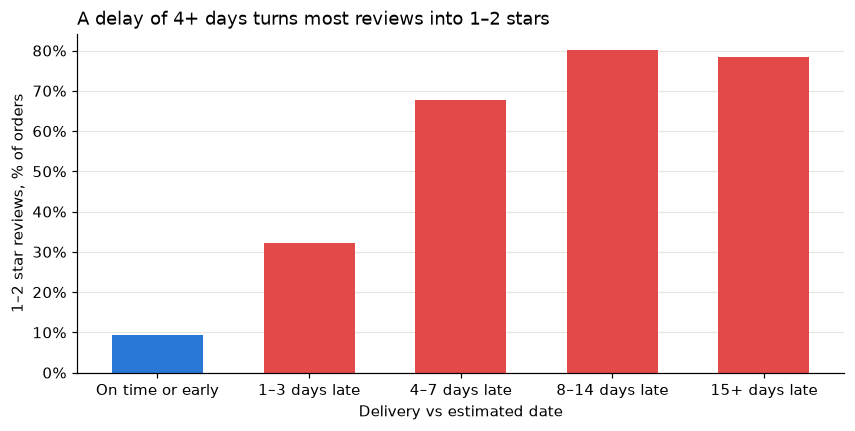

In [3]:
fig, ax = plt.subplots()
colors = [ACCENT] + [SIGNAL] * (len(by_bucket) - 1)
ax.bar(by_bucket.delay_bucket, by_bucket.low_score_share, color=colors, width=0.6)
ax.set_title("A delay of 4+ days turns most reviews into 1–2 stars")
ax.set_xlabel("Delivery vs estimated date")
ax.set_ylabel("1–2 star reviews, % of orders")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.grid(axis="x", visible=False)
plt.show()

## Size and significance of the effect
Difference of mean scores with a 95% bootstrap interval, Mann–Whitney U test
(scores are ordinal, so a rank test), and rank-biserial correlation as effect size.

In [4]:
def compare(name, a, b):
    diff, lo, hi = bootstrap_diff_ci(a, b)
    u, p = mannwhitneyu(a, b, alternative="two-sided")
    return {
        "comparison": name,
        "n_on_time": len(a),
        "n_late": len(b),
        "mean_on_time": a.mean(),
        "mean_late": b.mean(),
        "diff": diff,
        "ci_low": lo,
        "ci_high": hi,
        "mannwhitney_p": p,
        "rank_biserial": 1 - 2 * u / (len(a) * len(b)),
    }


on_time = df.loc[~df.is_late, "review_score"].to_numpy()
late = df.loc[df.is_late, "review_score"].to_numpy()
very_late = df.loc[df.delay_days >= 15, "review_score"].to_numpy()
effect = pd.DataFrame(
    [
        compare("late vs on time", on_time, late),
        compare("15+ days late vs on time", on_time, very_late),
    ]
)
effect.to_parquet(MARTS / "stats_delay_effect.parquet", index=False)
effect

,comparison,n_on_time,n_late,mean_on_time,mean_late,diff,ci_low,ci_high,mannwhitney_p,rank_biserial
0,late vs on time,89182,6378,4.291157,2.270618,-2.020540,-2.060042,-1.981484,0.0,-0.638184
1,15+ days late vs on time,89182,1333,4.291157,1.724681,-2.566476,-2.632421,-2.497987,0.0,-0.786841


## Does the gap hold inside each state? (confounding check)
If late deliveries were concentrated in states whose customers rate lower anyway, the gap would
shrink inside states. States with at least 300 reviewed deliveries and 30 late ones.

In [5]:
rows = []
for state, g in df.groupby("customer_state"):
    if len(g) < 300 or g.is_late.sum() < 30:
        continue
    rows.append(
        {
            "customer_state": state,
            "n": len(g),
            "late_share": g.is_late.mean(),
            "mean_on_time": g.loc[~g.is_late, "review_score"].mean(),
            "mean_late": g.loc[g.is_late, "review_score"].mean(),
        }
    )
by_state = pd.DataFrame(rows).assign(diff=lambda d: d.mean_late - d.mean_on_time)
by_state.to_parquet(MARTS / "stats_delay_by_state.parquet", index=False)
by_state.sort_values("diff")

,customer_state,n,late_share,mean_on_time,mean_late,diff
16,RN,467,0.092077,4.384434,1.767442,-2.616992
15,RJ,12172,0.119619,4.244214,1.914148,-2.330066
19,SE,331,0.151057,4.249110,1.940000,-2.309110
3,DF,2064,0.057171,4.265159,1.974576,-2.290583
12,PE,1573,0.094723,4.296348,2.033557,-2.262791
10,PA,929,0.107643,4.153197,1.920000,-2.233197
2,CE,1267,0.137332,4.242452,2.040230,-2.202222
0,AL,393,0.208651,4.299035,2.134146,-2.164889
17,RS,5309,0.060463,4.312550,2.205607,-2.106943
8,MS,699,0.097282,4.362916,2.294118,-2.068798


## …and inside the largest categories?

In [6]:
top_cats = df.main_category.value_counts().head(5).index
pd.DataFrame(
    [
        {
            "category": c,
            "n": len(g),
            "mean_on_time": g.loc[~g.is_late, "review_score"].mean(),
            "mean_late": g.loc[g.is_late, "review_score"].mean(),
        }
        for c, g in df[df.main_category.isin(top_cats)].groupby("main_category")
    ]
).assign(diff=lambda d: d.mean_late - d.mean_on_time)

,category,n,mean_on_time,mean_late,diff
0,bed_bath_table,9086,4.148100,2.229730,-1.918370
1,computers_accessories,6468,4.205048,2.273399,-1.931649
2,furniture_decor,6095,4.215700,2.332574,-1.883126
3,health_beauty,8530,4.385998,2.342314,-2.043684
4,sports_leisure,7431,4.379554,2.166667,-2.212887


## Where does logistics fail?

In [7]:
deliv = db.sql("select * from mart_delivery_performance where is_analysis_period").df()
states = (
    deliv.groupby("customer_state")
    .agg(
        orders=("order_id", "count"),
        late_rate=("is_late", "mean"),
        avg_delivery_days=("delivery_days", "mean"),
    )
    .query("orders >= 500")
    .sort_values("late_rate", ascending=False)
)
states.head(10)

,orders,late_rate,avg_delivery_days
customer_state,,,
MA,713,0.175316,21.474053
CE,1273,0.138256,21.171249
BA,3253,0.121734,19.276975
RJ,12310,0.121446,15.224127
PA,942,0.112527,23.709130
ES,1992,0.107430,15.710341
PB,516,0.104651,20.356589
MS,701,0.097004,15.544936
PE,1587,0.096408,18.396975


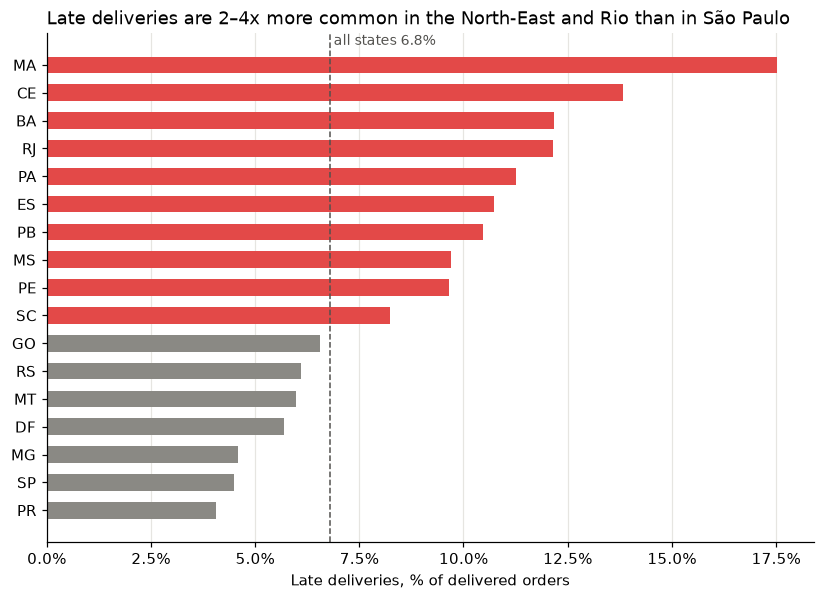

In [8]:
# every state with 500+ delivered orders; above-average states in the signal colour
shown = states.iloc[::-1]
overall = deliv.is_late.mean()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    shown.index,
    shown.late_rate,
    color=[SIGNAL if r > overall else MUTED for r in shown.late_rate],
    height=0.6,
)
ax.axvline(overall, color="#52514e", linewidth=1, linestyle="--")
ax.text(
    overall,
    len(shown) - 0.4,
    f" all states {overall:.1%}",
    fontsize=9,
    color="#52514e",
    va="bottom",
)
ax.set_title("Late deliveries are 2–4x more common in the North-East and Rio than in São Paulo")
ax.set_xlabel("Late deliveries, % of delivered orders")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
plt.show()

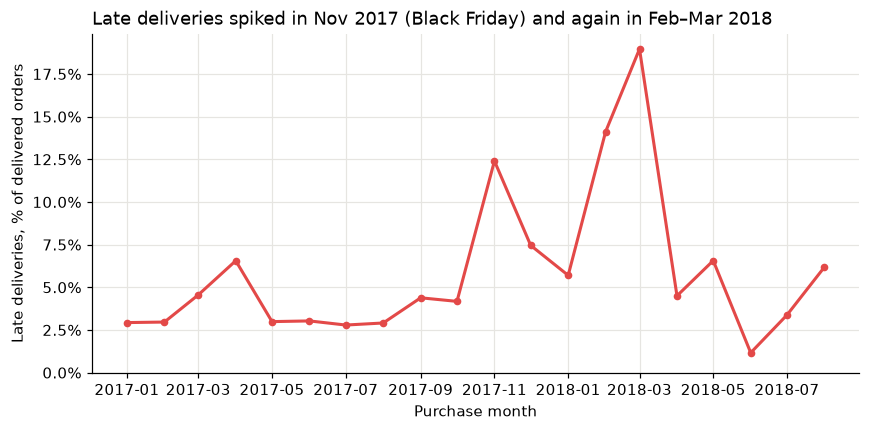

In [9]:
monthly_late = deliv.groupby("purchase_month").is_late.mean()
fig, ax = plt.subplots()
ax.plot(
    monthly_late.index, monthly_late.values, color=SIGNAL, linewidth=2, marker="o", markersize=4
)
ax.set_title("Late deliveries spiked in Nov 2017 (Black Friday) and again in Feb–Mar 2018")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Late deliveries, % of delivered orders")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(bottom=0)
plt.show()

## Sellers

In [10]:
sellers = db.sql("""
    select seller_id, seller_state, n_orders, late_rate, avg_review_score
    from dim_sellers where n_orders >= 50
""").df()
print(f"{len(sellers)} sellers with 50+ orders; median late rate {sellers.late_rate.median():.1%}")
sellers.sort_values("late_rate", ascending=False).head(10)

420 sellers with 50+ orders; median late rate 5.8%


,seller_id,seller_state,n_orders,late_rate,avg_review_score
199,54965bbe3e4f07ae045b90b0b8541f52,PR,78,0.301370,3.000000
406,beadbee30901a7f61d031b6b686095ad,SP,63,0.238095,3.936508
303,a49928bcdf77c55c6d6e05e09a9b4ca5,SP,98,0.218750,3.010204
316,712e6ed8aa4aa1fa65dab41fed5737e4,SC,79,0.207792,3.384615
265,06a2c3af7b3aee5d69171b0e14f0ee87,MA,391,0.190722,3.994832
313,d20b021d3efdf267a402c402a48ea64b,SP,77,0.189189,3.802632
263,cac4c8e7b1ca6252d8f20b2fc1a2e4af,SP,72,0.183099,3.591549
261,88460e8ebdecbfecb5f9601833981930,PR,233,0.181034,3.469828
235,ea566164622c6b439516ab18062c42cd,SP,50,0.180000,3.780000
200,6039e27294dc75811c0d8a39069f52c0,SP,64,0.174603,3.687500


In [11]:
db.sql("""
    with s as (select seller_id, late_rate, n_orders from dim_sellers where n_orders >= 50),
         ranked as (select *, ntile(10) over (order by late_rate desc) as decile from s)
    select decile = 1 as worst_10pct_sellers,
           count(*) as sellers,
           sum(n_orders) as orders,
           sum(late_rate * n_orders) / sum(n_orders) as late_rate
    from ranked group by 1
""").df()

,worst_10pct_sellers,sellers,orders,late_rate
0,True,42,4919.0,0.154076
1,False,378,68917.0,0.061882


## Findings
- **Late delivery goes with far worse reviews**: on-time orders average
  4.29 stars, late ones 2.27 (difference −2.02, 95% CI −2.06 to −1.98; Mann–Whitney p < 0.001;
  rank-biserial −0.64, a large effect). 15+ days late: −2.57.
- **Four or more days late flips the review**: the share of 1–2 star reviews goes from 9% (on time)
  to 32% (1–3 days late) and 68% (4–7 days late).
- **The gap holds inside every state** (−1.6 to −2.6 stars across 21 states) and inside the five
  largest categories (−1.9 to −2.2), so it is not explained by where or what people buy.
  It is still an observational association.
- **Where it fails**: late rates spiked in the Black Friday month (12.4% in Nov 2017) and again in
  Feb–Mar 2018 (14.1% and 19.0%), against about 3% in calm months of 2017; by state, from 4.5% in SP to 12.1%
  in RJ and 17.5% in MA;
  the worst 10% of sellers with 50+ orders (42 sellers) are late on 15.4% of orders vs 6.2% for the rest.